# Tarea I
#### Física IV FS0530 Grupo 01.
#### Profesor: Dr. Jesús Espinoza Valverde.
#### Estudiante: Basilio Antonio Salazar Núñez C07146.
#### Universidad de Costa Rica II Semestre 2026.

## Información del Enunciado

Cuando la luz coherente incide sobre dos ranuras de ancho finito, el patrón de intensidad observado en una pantalla combina interferencia y difracción:

$$
I(y) = I_0 \left[ \frac{\sin(\beta/2)}{\sin(\beta/2)} \right]^2 \cos^2 \left( \frac{\phi}{2} \right) \;\;\;\;\;\; (1)
$$

con

$$
\beta = \frac{2\pi a}{\lambda R}y, \;\;\; \phi= \frac{2\pi d}{\lambda R}y \;\;\;\;\;\; (2)
$$

<br>

Aquí, $a$ es el ancho de cada ranura, $d$ la separación entre sus centros, $\lambda$ la longitud de onda, $R$ la distancia a la pantalla e $I_o$ la intensidad máxima.

<br>

Para esta tarea, considere conocidos

$$
R = 1.50\;m, \;\;\;  \lambda=632.38\;nm
$$

## a) Carga y exploración de datos

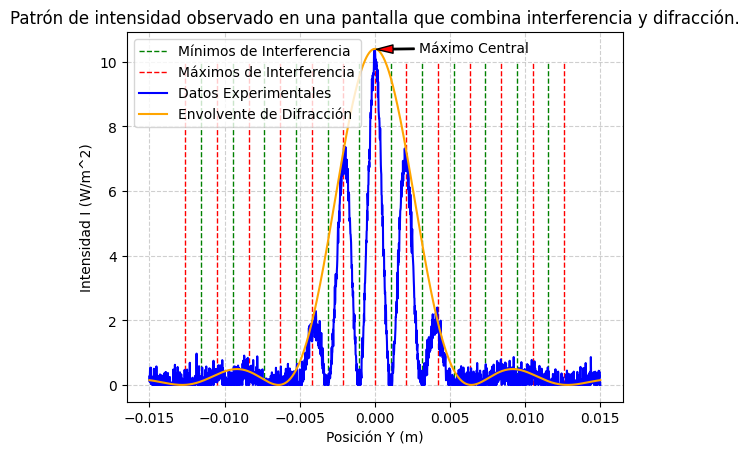

In [33]:
# --------------------- Librerias para todo el Notebook --------------------- #

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from decimal import Decimal

# --------------------- Datos --------------------- #

datos = pd.read_csv(r'C:\Users\Tech\Desktop\datos_experimentales_difraccion.csv', delimiter=',') # Carga del archivo, varía según donde se encuentre el archivo #
y = datos["y_m"].to_numpy() # Valores eje x, posición en el eje y, primera columna del CSV #
I = datos["Intensidad"].to_numpy() # Valores eje y, intensidad, segunda columna del CSV #

# --------------------- Máximo Central --------------------- #

posicion_maximo_central = y[np.argmax(I)] # Se busca la posición en el arreglo "I" con la mayor potencia. En esa misma posición, pero en en arreglo "y" se encuentra el máximo central #
plt.annotate("Máximo Central", xy=(posicion_maximo_central, max(I)), xytext=(posicion_maximo_central + 0.003, max(I) * 0.99),arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6)) # Flecha que señala el máximo central #

# --------------------- Franjas de Interferencia Destructiva --------------------- #

m_des=6 # Orden de los mínimos de interferencia # 
m_valores_min = np.arange(-m_des, m_des)

R = 1.50 # Distancia horizontal del centro entre las dos ranuras a la pantalla (m) # 
λ = 632.8e-9  # Longitud de onda (m) # 
d_interferencia =  4.52e-4  # Separación entre las ranuras, estimada de la gráfica para obtener los patrones de interferencia. Se obtiene en la parte b) # 
    
y_minimos = R * λ * (m_valores_min + 0.5) / d_interferencia # Posiciones con los mínimos de interferencia #

etiqueta_colocada = False  # Controla que la etiqueta solo se utilice una vez #

for pos_y in y_minimos: # Ciclo para trazar cada mínimo de interferencia #
    
    if not etiqueta_colocada: # Si es la primera línea, se asigna el texto de la leyenda # 
        plt.vlines(x=pos_y, ymin=0, ymax=10, color='green', linestyle='--', linewidth=1, alpha=1, label='Mínimos de Interferencia')
        etiqueta_colocada = True
        
    else: # Para las demás líneas, no se duplica la leyenda #
        plt.vlines(x=pos_y, ymin=0, ymax=10, color='green', linestyle='--', linewidth=1, alpha=1)

# --------------------- Franjas de Interferencia Constructiva --------------------- #

m_con=6 # Orden de los máximos de interferencia # 
m_valores_max = np.arange(-m_con, m_con+1)

R = 1.50 # Distancia horizontal del centro entre las dos ranuras a la pantalla (m) # 
λ = 632.8e-9  # Longitud de onda (m) # 
d_interferencia =  4.52e-4  # Separación entre las ranuras, estimada de la gráfica para obtener los patrones de interferencia. Se obtiene en la parte b) # 
    
y_maximos = R * λ * (m_valores_max) / d_interferencia # Posiciones con los máximos de interferencia #

etiqueta_colocada = False  # Controla que la etiqueta solo se utilice una vez #

for pos_y in y_maximos: # Ciclo para trazar cada máximo de interferencia #
    
    if not etiqueta_colocada: # Si es la primera línea, se asigna el texto de la leyenda # 
        plt.vlines(x=pos_y, ymin=0, ymax=10, color='red', linestyle='--', linewidth=1, alpha=1, label='Máximos de Interferencia')
        etiqueta_colocada = True
        
    else: # Para las demás líneas, no se duplica la leyenda #
        plt.vlines(x=pos_y, ymin=0, ymax=10, color='red', linestyle='--', linewidth=1, alpha=1)

# --------------------- Envolvente de Difracción --------------------- #

# Los valores de a_envolvente y I_0_envolvente se obtienen en la parte b) #

a_envolvente = 1.48e-4 # Ancho de las ranuras (m), estimada de la gráfica para obtener la envolvente de difracción # 
I_0_envolvente = 10.4 # Intensidad máxima (W/m^2), estimada de la gráfica para obtener la envolvente de difracción #

def envolvente(y): # Función para calcular la envolvente de difracción #
    
    beta = (2*np.pi*a_envolvente)*y/(λ*R)      
    return I_0_envolvente * (np.sin(beta/2)/(beta/2))**2 

y_envolvente = np.linspace(np.min(y), np.max(y), 1000) # Se generan 1000 posiciones igualmente espaciadas para evaluar la intensidad #   
I_0_envolvente = envolvente(y_envolvente) # Curva de la envolvente de difracción #

# --------------------- Gráfica --------------------- #

plt.title("Patrón de intensidad observado en una pantalla que combina interferencia y difracción.") # Título del gráfico #
plt.plot(y, I, label='Datos Experimentales', color='blue') # Curva con los datos experimentales #
plt.plot(y_envolvente, I_0_envolvente,label='Envolvente de Difracción', color='orange')  # Curva con la envolvente de difracción #
plt.xlabel("Posición Y (m)") # Título eje x #
plt.ylabel("Intensidad I (W/m^2)") # Título eje y #
plt.grid(True, linestyle='--', alpha=0.6) # Muestra la grilla #
plt.legend(loc='upper left') # Muestra las leyendas #
plt.show() # Muestra el gráfico #


### Identificación visual de las principales características del patrón ##

La línea azul corresponde a los datos experimentales. 

La línea naranja es la envolvente de difracción. Los mínimos de difracción se encuentran en los puntos donde la curva naranja toca el eje horizontal. 

La intensidad máxima en el centro de la gráfica es el máximo central. 

Las líneas punteadas verdes corresponden a los mínimos de interferencia. Se marcan los primeros 6 mínimos que se pueden identificar en el gráfico, los siguientes mínimos no son fáciles de visualizar. Para obtener las líneas igualmente espaciadas se utilizó una versión modificada (para interferencia destructiva) de la Ecuación 4 y la estimación para el valor $d$ de la sección b).

Las líneas punteadas rojas corresponden a los máximos de interferencia. Se marcan los primeros 6 máximos + el máximo central que se puden identificar en el gráfico, los siguientes máximos no son fáciles de visualizar. En $m \pm 3 $ y $m \pm 6 $ parece que existen un máximos faltantes, pero esto se analiza en la sección d). Para obtener las líneas igualmente espaciadas se utilizó la Ecuación 4 y la estimación para el valor $d$ de la sección b). 

## b) Estimaciones iniciales a partir de la gráfica

### Ancho de las ranuras finitas, $ a $ ###

A partir de una inspección visual de la gráfica experimental, se puede notar que los primeros mínimos de difracción se encuentran cerca de las posiciones $ y = \pm 0,0064 \; m $.

Se tiene que, para una sola ranura, los mínimos de difracción están dados por;    

<br>

$$ \sin(\theta) =  \frac{m \lambda}{a} \;\;\;\;\;\; (3) $$

Donde:

* $\theta$, ángulo de difracción.
* $m$, orden del mínimo, $m = \pm 1, \pm 2, \pm 3, \dots$.
* $a$, ancho de la ranura.

Para  ángulos pequeños se puede utilzar la aproximación $ \sin(\theta) = y_m/R $. Con $y_m$ la distancia vertical de la m-ésima banda oscura al centro del patrón y $R$ la distancia de la ranura a la pantalla.

Con esto, se puede utilizar la Ecuación 3 y despejar el valor de $a$ a partir de $y_1=0,0064 \; m$.

<br>

$$ a =  \frac{m \lambda R}{y_m} = \frac{632,8 \times 10^{-9} m* 1,50 m}{0,0064 m} \approx 1,48 \times 10^{-4} m $$

### Separación entre los centros de las ranuras, $ d $ ###

Como el fenómeno de máximos faltantes no puede suceder antes del primer mínimo de difracción ($y = \pm 0,0064 \; m$, obtenido en el cálculo de $a$), se puede notar en la gráfica que los segundos máximos de interferencia (después del máximo central) se encuentran aproximadamente en $ y = \pm 0,0021 \; m $.

Se tiene que, para dos ranuras, los máximos de interferencia están dados por;   

<br>

$$ \sin(\theta) =  \frac{m \lambda}{d} \;\;\;\;\;\; (4) $$

Donde:

* $\theta$, ángulo de interferencia.
* $m$, orden del máximo, $m = 0, \pm 1, \pm 2, \pm 3, \dots$.
* $d$, separación entre las ranuras.

Para  ángulos pequeños se puede utilzar la aproximación $ \sin(\theta) = y_m/R $. Con $y_m$ la distancia vertical de la m-ésima banda brillante al centro del patrón y $R$ la distancia del centro de las ranuras a la pantalla.

Con esto, se puede utilizar la Ecuación 4 y despejar el valor de $d$ a partir de $y_1=0,0021 \; m$.

<br>

$$ d =  \frac{m \lambda R}{y_m} = \frac{632,8 \times 10^{-9} m* 1,50 m}{0,0021 m} \approx 4,52 \times 10^{-4} m $$

### Intensidad máxima, $ I_o $ ###

Según la gráfica, para $y \rightarrow 0$ y $ I(y) \rightarrow 10,4 W/m^2$. Si se utilizan las Ecuaciones 1 y 2, se tiene que la potencia es,

$$
I(y) = I_o \left[ \frac{\sin \left(\frac{\pi a}{\lambda R}y\right)}{\frac{\pi a}{\lambda R}y} \right]^2 \cos^2 \left( \frac{2\pi d}{\lambda R}y \right) \;\;\;\;\;\; (5)
$$

<br>

Si se calcula el límite de la Ecuación 5 para $y \rightarrow 0$ entonces,


$$
\lim_{y \to 0} I(y) = 10,4 W/m^2 = I_0 \; \lim_{y \to 0}  \left[ \frac{\sin \left(\frac{\pi a}{\lambda R}y\right)}{\frac{\pi d}{\lambda R}y} \right]^2 \lim_{y \to 0} \; \cos^2 \left( \frac{2\pi d}{\lambda R}y \right) = I_0  
$$

<br>

Por lo tanto,  $ I_0 \approx 10,4 W/m^2 $.


## c) Ajuste no lineal

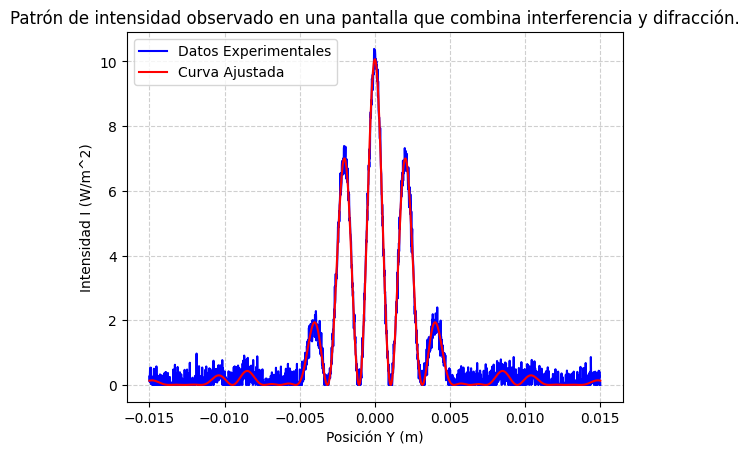

In [34]:
# ----------- Constantes ----------- # 

R = 1.50 # Distancia horizontal del centro entre las dos ranuras a la pantalla (m) # 
λ = 632.8e-9 # Longitud de onda (m) #
a_initial_guess = 1.48e-4 # Ancho de las ranuras (m), estimada de la gráfica parte b)# 
d_initial_guess = 4.52e-4 # Separación entre las ranuras, estimada de la gráfica parte b) # 
I_0_initial_guess = 10.4 # Intensidad máxima (W/m^2), estimada de la gráfica parte b) #

# ----------- Modelo Teórico ----------- # 

def intensidad(y,a,d,I_0): # Función para calcular la intensidad #
    
    beta = (2*np.pi*a)*y/(λ*R)      
    phi= (2*np.pi*d)*y/(λ*R)
    
    return I_0 * (np.sin(beta/2)/(beta/2))**2 *(np.cos(phi/2))**2 

# ----------- Curva No Lineal ----------- # 

initial_guess = [a_initial_guess, d_initial_guess, I_0_initial_guess] # Lista con las estimaciones iniciales #

params, covariance = curve_fit(intensidad,y,I,p0=initial_guess,maxfev=10000) # Ajuste no lineal #

a_fit = params[0] # Valor óptimo de a, obtenido con el ajuste no lineal #
d_fit = params[1] # Valor óptimo de d, obtenido con el ajuste no lineal #
I_0_fit = params[2] # Valor óptimo de I_0, obtenido con el ajuste no lineal #

sigma_a = np.sqrt(covariance[0,0]) # Desviación estándar de a, obtenida con el ajuste no lineal #
sigma_d = np.sqrt(covariance[1,1]) # Desviación estándar de d, obtenida con el ajuste no lineal #
sigma_I_0 = np.sqrt(covariance[2,2]) # Desviación estándar de I_0, obtenida con el ajuste no lineal #

# ----------- Gráficas ----------- # 

y_curve = np.linspace(np.min(y), np.max(y), 1000) # Se generan 1000 posiciones igualmente espaciadas para evaluar la intensidad #   
I_0_curve = intensidad(y_curve,a_fit,d_fit,I_0_fit) # Curva de intensidad ajustada #

plt.title("Patrón de intensidad observado en una pantalla que combina interferencia y difracción.") # Título del gráfico #
plt.plot(y, I, label='Datos Experimentales', color='blue') # Curva con los datos experimentales #
plt.plot(y_curve, I_0_curve, label='Curva Ajustada', color='red') # Curva ajustada #
plt.xlabel("Posición Y (m)") # Título eje x #
plt.ylabel("Intensidad I (W/m^2)") # Título eje y #
plt.grid(True, linestyle='--', alpha=0.6) # Muestra la grilla #
plt.legend(loc='upper left') # Muestra la leyenda #

## d) Análisis físico y discusión

### Comparación del valor obtenidos con el valor real ###

In [35]:
# ----------- Reporte de Valores Obtenidos ----------- # 

incer_a = float(f"{sigma_a:.1g}") # Incertidumbre a. La incertidumbre es la desviación estándar con solo un decimal #
incer_d = float(f"{sigma_d:.1g}") # Incertidumbre d. La incertidumbre es la desviación estándar con solo un decimal #
incer_I_0 = float(f"{sigma_I_0:.1g}") # Incertidumbre I_0. La incertidumbre es la desviación estándar con solo un decimal #

a_final = round(a_fit,max(0, -Decimal(str(incer_a)).normalize().as_tuple().exponent)) # Valor a final según la cantidad de decimales de la incertidumbre #
d_final = round(d_fit,max(0, -Decimal(str(incer_d)).normalize().as_tuple().exponent)) # Valor d final según la cantidad de decimales de la incertidumbre #
I_0_final = round(I_0_fit,max(0, -Decimal(str(incer_I_0)).normalize().as_tuple().exponent)) # Valor I_0 final según la cantidad de decimales de la incertidumbre #

print(f"Ancho de ranura óptimo (a): {a_final} ± {incer_a} m") # Valor óptimo de a con su incertidumbre #
print(f"Separación óptima (d): {d_final} ± {incer_d} m") # Valor óptimo de d con su incertidumbre #
print(f"Intensidad máxima óptima (I_0): {I_0_final} ± {incer_I_0} W/m^2") # Valor óptimo de I_0 con su inceritudmbre #

# ----------- Error Relativo ----------- # 

error_a= float(f"{100*abs(a_initial_guess-a_final)/a_final:.3g}") # Error relativo a. Se utilizan tres cifras significativas #
error_d=  float(f"{100*abs(d_initial_guess-d_final)/d_final:.3g}") # Error relativo d. Se utilizan tres cifras significativas # 
error_I_0= float(f"{ 100*abs(I_0_initial_guess-I_0_final)/I_0_final:.3g}") # Error relativo I_0. Se utilizan tres cifras significativas # 

print("---------------------------------------------------------------")
print(f"Error relativo ancho de ranura (a): {error_a} %")
print(f"Error relativo separación de ranuras (d): {error_d} %")
print(f"Error relativo intensidad máxima (I_0): {error_I_0} %")


Ancho de ranura óptimo (a): 0.0001499 ± 4e-07 m
Separación óptima (d): 0.0004507 ± 3e-07 m
Intensidad máxima óptima (I_0): 10.07 ± 0.02 W/m^2
---------------------------------------------------------------
Error relativo ancho de ranura (a): 1.27 %
Error relativo separación de ranuras (d): 0.288 %
Error relativo intensidad máxima (I_0): 3.28 %


Los valores óptimos obtenidos fueron: 

* Ancho de ranura óptimo (a): 0.0001499 ± 4e-07 m
* Separación óptima (d): 0.0004507 ± 3e-07 m
* Intensidad máxima óptima (I_0): 10.07 ± 0.02 W/m^2

Para comparar las estimaciones iniciales con los valores óptimos, se utiliza el porcentaje de error relativo. Los errores relativos obtenidos fueron: 

* Error relativo ancho de ranura (a): 1.27 %
* Error relativo separación de ranuras (d): 0.288 %
* Error relativo intensidad máxima (I_0): 3.28 %

En general, las estimaciones iniciales fueron adecuadas, ninguno de los errores relativos supera el 4%.  Las diferencias entre los valores estimados y óptimos se atribuyen a la dificultad que existe en la gráfica de valores experimentales para estimar la posición (y) de un valor específico. 

### Máximos faltantes ###

En un experimento de interferencia y difracción de doble ranura, el patrón de intensidad está determinado por la combinación de la interferencia entre las ranuras y la difracción individual de cada una de ellas. La relación entre la separación de ranuras ($d$) y el ancho de ranura ($a$) es el factor que define los máximos faltantes. El máximo faltante ocurre cuando coinciden exactamente las posiciones de un máximo de interferencia y un mínimo de difracción. Si $d/a$ es un número entero, el fenómeno de máximos faltantes se presenta para aquellos órdenes de interferencia ($m_i$) que coinciden con los mínimos de difracción ($m_d$). La Ecuación 6 resume esta relación:

$$ m_i = \frac{d}{a}m_d \;\;\;\;\;\; (6)
$$

Si se consideran los valores óptimos, 

$$ \frac{m_i}{m_d} = \frac{d}{a} = \frac{ 4,507 \times 10^{-4}m}{1,499 \times 10^{-4}m} \approx 3 $$

Con esto, en todos máximos de interferencia múltiplos de 3 se va a presentar el fenómeno de máximos faltantes. Para los datos experimentales, los máximos faltantes se pueden notar en $m_i = \pm 3$ y $m_i = \pm 6$. En la gráfica de la parte a) el fenómeno se aprecia cuando las líneas rojas coinciden con los puntos donde la curva naranja toca el eje horizontal. En dichos puntos deberían existir "picos" de interferencia constructiva, pero la envolvente de difracción los "cancela". 